# TokoKita: leakage-safe churn prediction with out-of-time validation

*Originally developed as a university course project (AI for Data & Predictive Analytics), rebuilt and extended independently.*

**Question.** An e-commerce marketplace ("TokoKita") sees repeat purchases fall. Which *active* customers are likely to place **no order in the next 30 days**, and who is actually worth a retention offer?

**What this notebook does**

| Part | Content |
|:-:|---|
| 1 | Synthetic data from a customer-lifecycle simulation (seeded, deterministic) |
| 2 | Snapshot design: features at `as_of`, label in `(as_of, as_of + 30d]`, purged temporal split |
| 3 | The evaluation trap: what label leakage looks like, and the automated audit that catches it |
| 4 | Four models (LR, RF, XGBoost, LightGBM), validation, isotonic calibration |
| 5 | Out-of-time test with customer-clustered bootstrap confidence intervals |
| 6 | Business decision: net benefit versus threshold, value-aware policy, sensitivity to assumptions |
| 7 | Conclusions and limitations |

All numbers below are produced by this notebook from `src/tokokita` (seed 42). The data is **synthetic**; nothing here describes a real company.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import sklearn, xgboost, lightgbm, matplotlib
from IPython.display import Image, Markdown, display

from tokokita import config as C
from tokokita import plots
from tokokita.features import FEATURE_COLUMNS, LABEL_COLUMN
from tokokita.pipeline import run_experiment

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def show(name):
    '''Render a figure from tokokita.plots, save it to reports/figures and display it.'''
    fig = plots.FIGURES[name](exp)
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plots.plt.close(fig)
    display(Image(filename=str(path)))


print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0


## 1. Run the experiment

`run_experiment` generates the data, builds the snapshot panel, applies the purged split, trains the four models, calibrates them, computes bootstrap intervals (1,000 customer-level resamples) and the economics. It takes a few minutes; every later cell only *reads* the result.

In [2]:
exp = run_experiment(n_boot=1000)
ds, split = exp.dataset, exp.split
print(f"customers: {len(ds.customers):,} | orders: {len(ds.transactions):,} | "
      f"{ds.transactions.order_date.min():%Y-%m-%d} to {ds.transactions.order_date.max():%Y-%m-%d}")
print(f"panel rows (active customer x snapshot): {len(exp.panel):,}")

customers: 3,000 | orders: 46,323 | 2023-01-04 to 2024-12-31
panel rows (active customer x snapshot): 42,840


## 2. Synthetic data

The generator (`src/tokokita/data.py`) is a small **customer lifecycle simulation**:

* each customer gets a latent value tier (low / medium / high), an individual order rate and basket size;
* a latent *defection date* is drawn from an exponential lifetime. Its hazard depends on tier, acquisition channel, age group and discount propensity;
* in the 20 to 60 days before defecting, the order rate **winds down**, so churn leaves a behavioural trace (falling frequency, growing recency) instead of being pure coin-flipping;
* orders are Poisson draws from a daily rate with a weekend effect and a Nov/Dec campaign lift.

The hidden state lives in a separate `latent` table that the feature pipeline never reads.

In [3]:
display(ds.customers.head(3))
display(ds.transactions.head(3))
summary = pd.Series({
    "customers": len(ds.customers),
    "orders": len(ds.transactions),
    "mean order value (IDR)": ds.transactions.order_value.mean(),
    "orders with discount": ds.transactions.discount_used.mean(),
    "customers with >= 1 order": ds.transactions.customer_id.nunique(),
    "missing values": int(ds.customers.isna().sum().sum() + ds.transactions.isna().sum().sum()),
})
summary

,customer_id,signup_date,age_group,gender,acquisition_channel
0,C00000,2023-02-27,36-45,F,paid_social
1,C00001,2024-05-09,55+,F,paid_search
2,C00002,2024-02-23,26-35,M,organic


,order_id,customer_id,order_date,order_value,product_category,channel,discount_used
0,O0000000,C00000,2023-04-01,"120,000.000",electronics,mobile_app,False
1,O0000001,C00000,2023-08-04,"91,300.000",home,mobile_app,True
2,O0000002,C00001,2024-06-30,"129,400.000",fashion,web,True


customers                     3,000.000
orders                       46,323.000
mean order value (IDR)      484,868.003
orders with discount              0.240
customers with >= 1 order     2,670.000
missing values                    0.000
dtype: float64

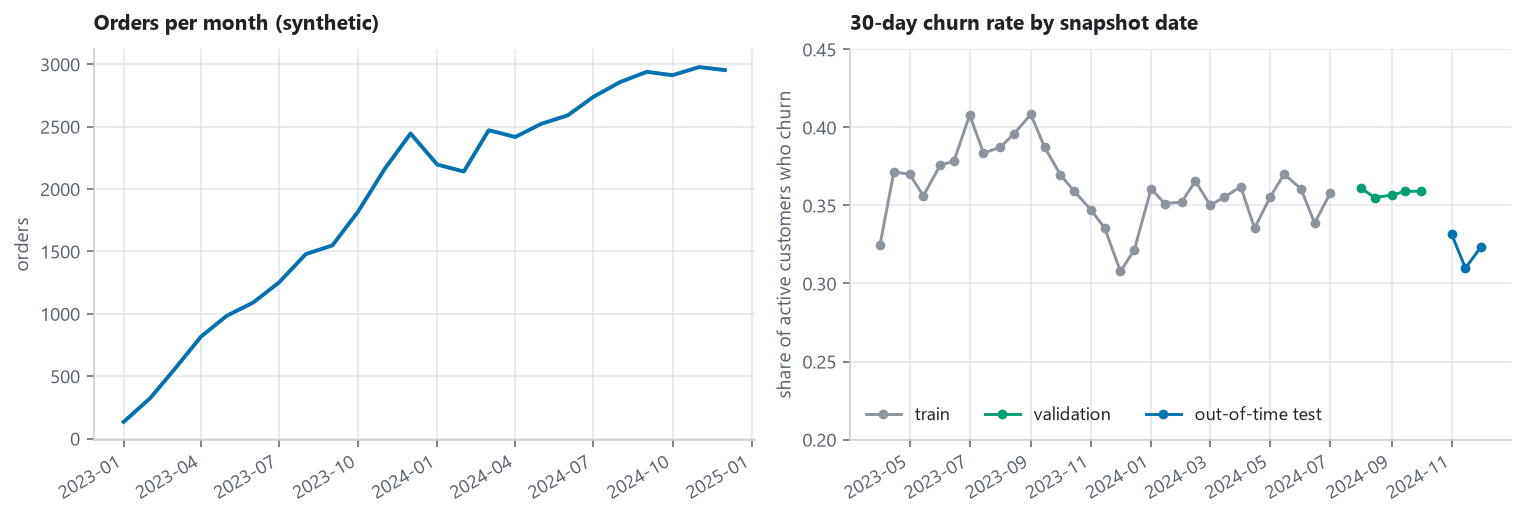

In [4]:
show("01_data_overview")

## 3. Problem framing: snapshots, labels, features, split

* **Active customer** at snapshot date `as_of`: at least one order in the previous 90 days.
* **Features** use only orders with `order_date <= as_of`.
* **Label** `churn_30d = 1` if the customer places **no** order in `(as_of, as_of + 30 days]`. The label window starts right after `as_of` (the original coursework left a 30-day gap, which shifted the question to days 31 to 60).
* **Snapshots** are taken on the 1st and 15th of every month, giving one row per active customer per snapshot.
* **Purged temporal split.** Labels look 30 days ahead, so a naive date cut would let the last training labels peek into the next period. Rows whose label window crosses a boundary are dropped.

| Set | Rule | Role |
|---|---|---|
| train | `as_of + 30d <= 2024-08-01` | fit models |
| validation | `2024-08-01 <= as_of`, `as_of + 30d <= 2024-11-01` | model selection, calibration, threshold |
| out-of-time test | `as_of >= 2024-11-01` | touched once, for the final report |

In [5]:
rows = []
for name, d in [("train", split.train), ("validation", split.val), ("out-of-time test", split.test)]:
    rows.append({"set": name, "rows": len(d), "snapshots": d.as_of.nunique(), "customers": d.customer_id.nunique(),
                 "first as_of": d.as_of.min().date(), "last as_of": d.as_of.max().date(),
                 "last label ends": (d.as_of.max() + pd.Timedelta(days=C.HORIZON_DAYS)).date(),
                 "churn rate": d[LABEL_COLUMN].mean()})
pd.DataFrame(rows).set_index("set")

,rows,snapshots,customers,first as_of,last as_of,last label ends,churn rate
set,,,,,,,
train,28369,31,2188,2023-04-01,2024-07-01,2024-07-31,0.359
validation,7259,5,1707,2024-08-01,2024-10-01,2024-10-31,0.358
out-of-time test,4321,3,1509,2024-11-01,2024-12-01,2024-12-31,0.322


In [6]:
groups = {
    "RFM": ["recency_days", "frequency_30d", "frequency_90d", "monetary_30d", "monetary_90d", "avg_order_value", "monetary_trend"],
    "Behaviour": ["unique_cats_90d", "category_diversity", "discount_rate", "channel_loyalty", "weekend_ratio"],
    "Lifecycle / tempo": ["tenure_days", "orders_total", "mean_gap_days", "recency_ratio"],
    "Momentum": ["orders_7d", "spend_7d", "ewm_frequency"],
    "Business": ["clv_estimate", "clv_decile"],
    "Demographics (one-hot)": [c for c in FEATURE_COLUMNS if c.startswith(("age_", "gender_", "acq_"))],
}
assert sorted(sum(groups.values(), [])) == sorted(FEATURE_COLUMNS)
pd.DataFrame({"features": {g: ", ".join(v) for g, v in groups.items()}, "count": {g: len(v) for g, v in groups.items()}})

,features,count
RFM,"recency_days, frequency_30d, frequency_90d, mo...",7
Behaviour,"unique_cats_90d, category_diversity, discount_...",5
Lifecycle / tempo,"tenure_days, orders_total, mean_gap_days, rece...",4
Momentum,"orders_7d, spend_7d, ewm_frequency",3
Business,"clv_estimate, clv_decile",2
Demographics (one-hot),"age_18-25, age_26-35, age_36-45, age_46-55, ag...",11


## 4. The evaluation trap: label leakage

The original coursework's first evaluation scored features computed at **1 December** against a label describing **November**. Those features already contained the outcome: a customer with no November order necessarily had `recency_days > 30` on 1 December, so a single feature separated the classes perfectly (AUC 1.0). The original analysis noticed this itself and switched to an out-of-time evaluation.

This rebuild keeps that discovery as a permanent guardrail. `tokokita.leakage.build_leaky_panel` recreates the overlapping-window mistake on the new data (features computed at the **end** of the label window), so the two pipelines can be compared on the same customers and labels.

In [7]:
leaky = exp.leakage["leaky_test"]
ct = pd.crosstab(leaky["recency_days"] > 30, leaky[LABEL_COLUMN])
ct.index = ["recency <= 30 days", "recency > 30 days"]
ct.columns = ["did not churn", "churned"]
print("Leaky features (computed at the end of the label window):")
display(ct)
print(f"AUC of recency_days alone, leaky: {exp.leakage['recency_auc_leaky']:.3f} | clean: {exp.leakage['recency_auc_clean']:.3f}")

Leaky features (computed at the end of the label window):


,did not churn,churned
recency <= 30 days,2931,42
recency > 30 days,0,1348


AUC of recency_days alone, leaky: 1.000 | clean: 0.737


In [8]:
comparison = pd.DataFrame({
    "AUC, leaky evaluation": exp.leakage["leaky_metrics"]["AUC"],
    "AUC, clean out-of-time": exp.test_metrics["AUC"],
})
comparison["inflation"] = comparison.iloc[:, 0] - comparison.iloc[:, 1]
display(comparison)
print("Features flagged by the single-feature audit (AUC >= 0.90):")
print("  leaky pipeline:", exp.leakage["audit_leaky"].query("strength >= 0.9")["feature"].tolist())
print("  clean pipeline:", exp.leakage["audit_clean"].query("strength >= 0.9")["feature"].tolist() or "none")

,"AUC, leaky evaluation","AUC, clean out-of-time",inflation
Logistic Regression,0.990,0.788,0.202
Random Forest,0.990,0.796,0.194
XGBoost,0.978,0.800,0.177
LightGBM,0.979,0.800,0.178


Features flagged by the single-feature audit (AUC >= 0.90):
  leaky pipeline: ['recency_days', 'frequency_30d', 'monetary_30d', 'ewm_frequency', 'recency_ratio']
  clean pipeline: none


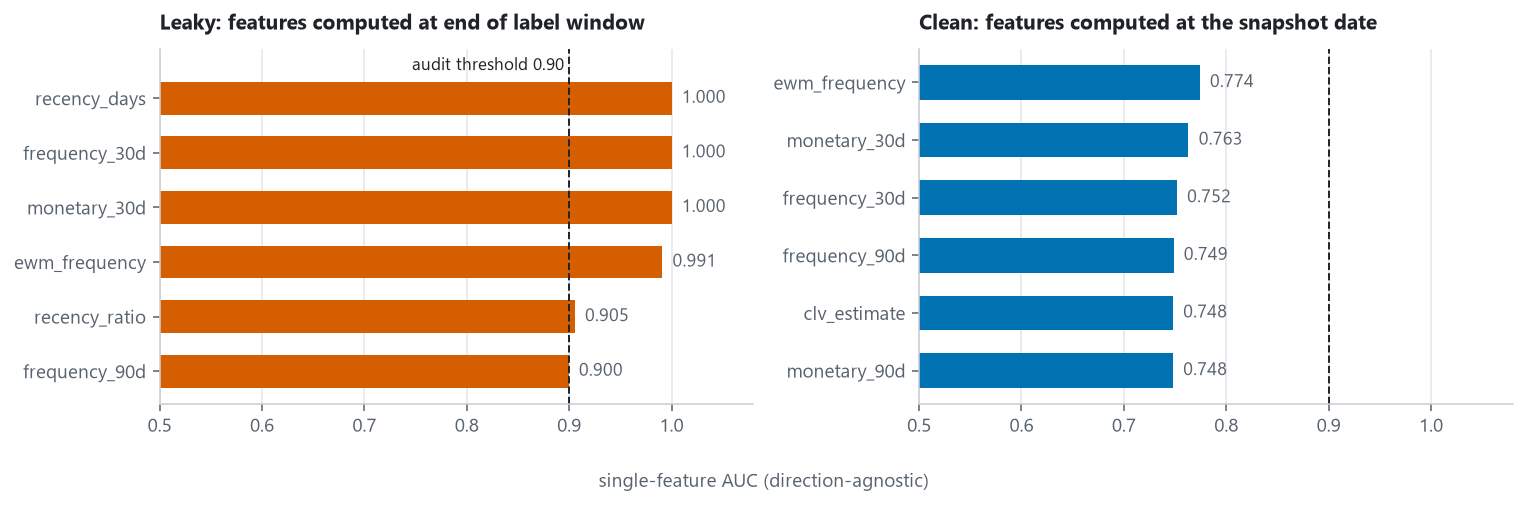

In [9]:
show("02_leakage_audit")

The unit tests in `tests/test_leakage.py` turn this into guarantees: features do not change when future transactions are tampered with; the label window is strictly after `as_of`; train and validation labels are fully known before the next period starts; and the audit flags the leaky panel but passes the clean one.

## 5. Models and validation

Four models, deliberately simple hyper-parameters (no heavy tuning; the point is a trustworthy evaluation, not a leaderboard):
Logistic Regression (standardised features), Random Forest, XGBoost and LightGBM. Compared with the original, class re-weighting is dropped (churn is about one third of rows, and re-weighting tends to distort probabilities), so the raw outputs can be read as probabilities. An **isotonic calibrator fitted on the validation set** is still applied before the economic analysis, as a safeguard; the reliability check in section 6 shows how much it actually matters.

In [10]:
display(exp.val_metrics)
print("Selected on validation AUC:", exp.selected)

,AUC,PR_AUC,Precision@10%,Recall@10%,Lift@10%,Brier,ECE
Logistic Regression,0.783,0.644,0.760,0.212,2.123,0.179,0.014
Random Forest,0.791,0.666,0.784,0.219,2.188,0.176,0.011
XGBoost,0.793,0.672,0.784,0.219,2.188,0.174,0.011
LightGBM,0.793,0.672,0.780,0.218,2.177,0.175,0.011


Selected on validation AUC: XGBoost


## 6. Out-of-time test

The test set contains snapshots from 1 November 2024 onward, after every training and validation label window has closed. Metrics are computed once. Because a customer appears in several snapshots, confidence intervals come from a **customer-clustered bootstrap** (1,000 resamples, identical resamples for every model so that differences are paired).

*Precision@10% / Recall@10%* refer to the 10% highest-risk rows; *ECE* is the weighted expected calibration error over 10 probability bins.

In [11]:
display(exp.test_metrics)
ci = exp.test_ci.copy()
ci["95% CI"] = ci.apply(lambda r: f"[{r.lo:.3f}, {r.hi:.3f}]", axis=1)
display(ci.pivot(index="model", columns="metric", values="95% CI").loc[exp.test_metrics.index, ["AUC", "PR_AUC", "Precision@10%", "Recall@10%", "Lift@10%", "Brier", "ECE"]])

,AUC,PR_AUC,Precision@10%,Recall@10%,Lift@10%,Brier,ECE
Logistic Regression,0.788,0.623,0.741,0.231,2.305,0.172,0.037
Random Forest,0.796,0.648,0.755,0.235,2.348,0.168,0.034
XGBoost,0.800,0.653,0.760,0.237,2.362,0.166,0.033
LightGBM,0.800,0.654,0.769,0.240,2.391,0.166,0.033


metric,AUC,PR_AUC,Precision@10%,Recall@10%,Lift@10%,Brier,ECE
Logistic Regression,"[0.770, 0.805]","[0.589, 0.659]","[0.689, 0.789]","[0.214, 0.247]","[2.133, 2.472]","[0.165, 0.179]","[0.026, 0.053]"
Random Forest,"[0.780, 0.813]","[0.616, 0.680]","[0.709, 0.802]","[0.219, 0.253]","[2.185, 2.526]","[0.161, 0.175]","[0.024, 0.049]"
XGBoost,"[0.783, 0.817]","[0.621, 0.686]","[0.713, 0.810]","[0.220, 0.253]","[2.193, 2.530]","[0.159, 0.174]","[0.021, 0.047]"
LightGBM,"[0.783, 0.817]","[0.622, 0.687]","[0.715, 0.815]","[0.221, 0.255]","[2.209, 2.549]","[0.159, 0.174]","[0.022, 0.047]"


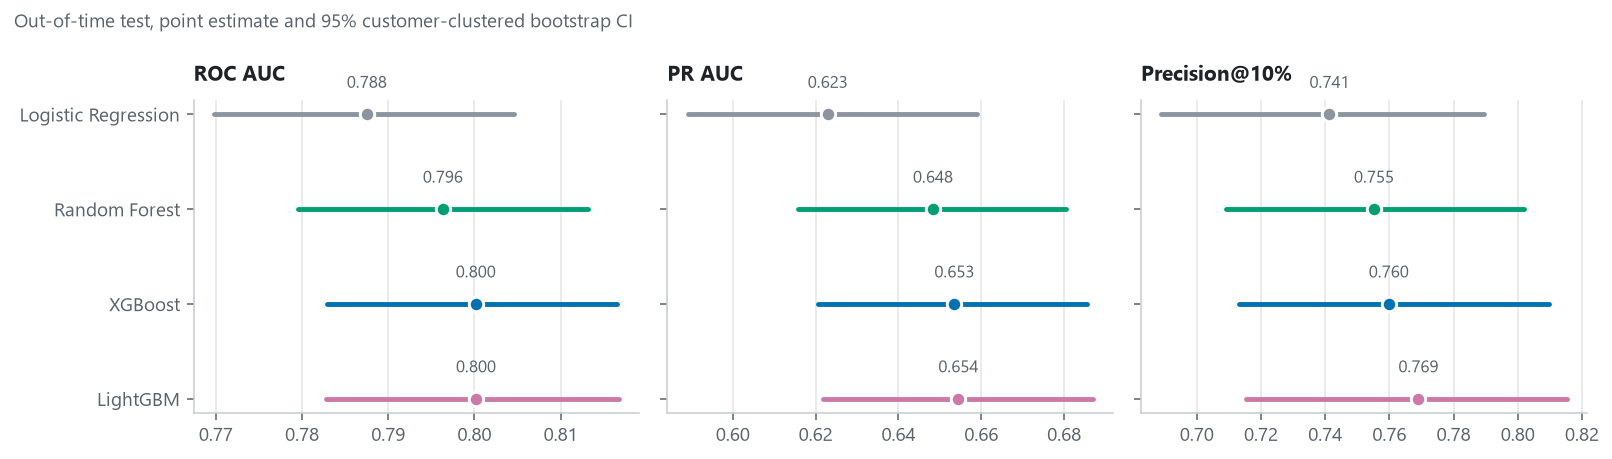

,AUC(XGBoost) - AUC(model),lo,hi
model,,,
Logistic Regression,0.013,0.007,0.018
Random Forest,0.004,0.001,0.007
XGBoost,0.000,0.000,0.000
LightGBM,-0.000,-0.001,0.001


In [12]:
show("03_model_comparison_oot")
display(exp.paired_auc)

In [13]:
d = exp.paired_auc
others = d.drop(index=exp.selected)
indistinct = others[(others["lo"] <= 0) & (others["hi"] >= 0)].index.tolist()
distinct = others[others["lo"] > 0].index.tolist()
display(Markdown(
    f"**Reading the paired differences.** Against `{exp.selected}` (best on validation), the 95% interval of the AUC gap "
    f"excludes zero for: {', '.join(distinct) or 'none'}; it includes zero (not distinguishable) for: {', '.join(indistinct) or 'none'}. "
    "The gaps are small in absolute terms (see the table), so model choice should also weigh simplicity and speed."))

**Reading the paired differences.** Against `XGBoost` (best on validation), the 95% interval of the AUC gap excludes zero for: Logistic Regression, Random Forest; it includes zero (not distinguishable) for: LightGBM. The gaps are small in absolute terms (see the table), so model choice should also weigh simplicity and speed.

### Calibration

,Brier raw,Brier calibrated,ECE raw,ECE calibrated
Logistic Regression,0.172,0.172,0.047,0.037
Random Forest,0.167,0.168,0.036,0.034
XGBoost,0.166,0.166,0.032,0.033
LightGBM,0.166,0.166,0.031,0.033


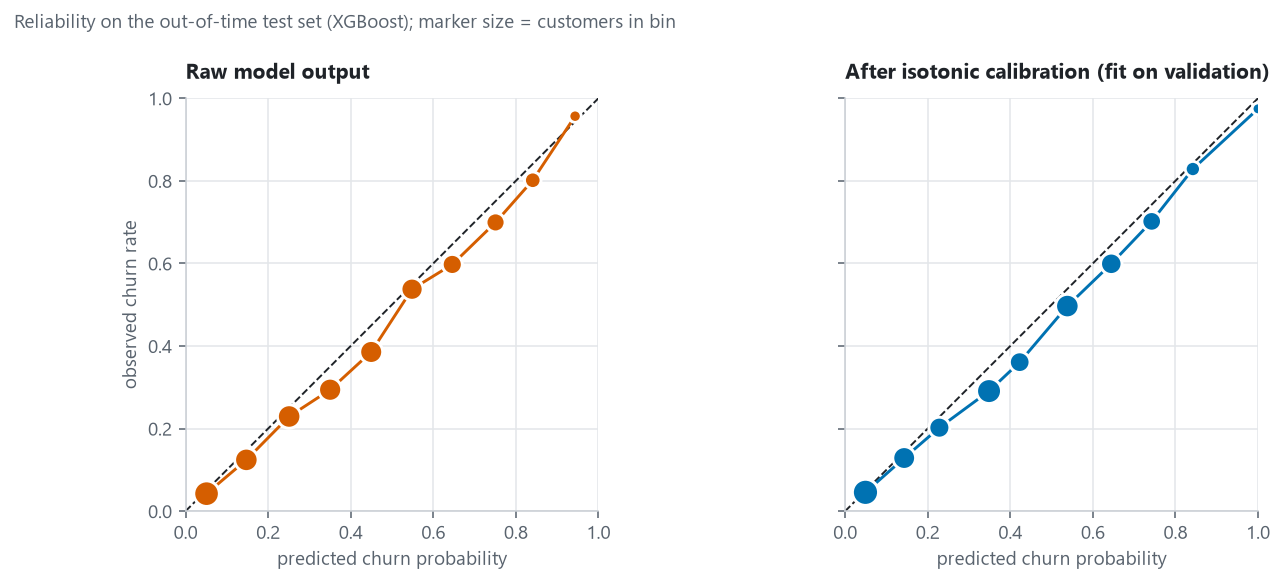

In [14]:
cal = pd.DataFrame({
    "Brier raw": exp.test_metrics_uncalibrated["Brier"], "Brier calibrated": exp.test_metrics["Brier"],
    "ECE raw": exp.test_metrics_uncalibrated["ECE"], "ECE calibrated": exp.test_metrics["ECE"],
})
display(cal)
show("04_calibration")

### Where is the signal?

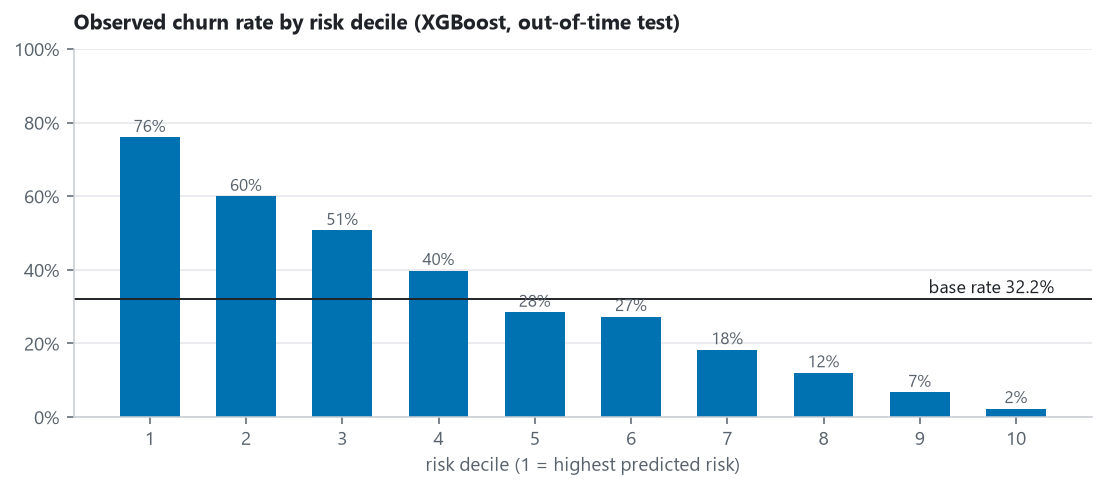

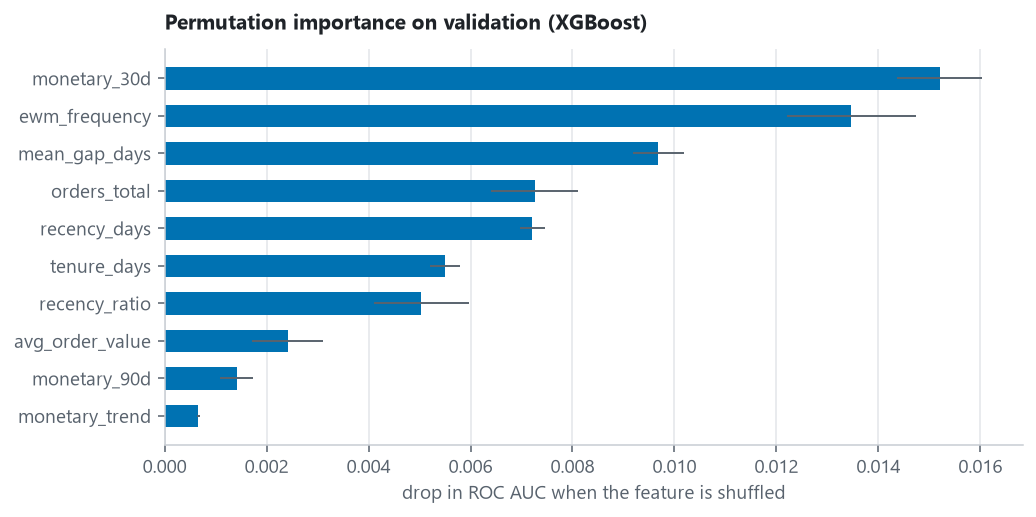

In [15]:
show("05_lift_by_decile")
show("08_feature_importance")

## 7. From scores to a decision: net benefit

A churn score is only useful if acting on it pays. The decision is whether to send a retention offer (email plus voucher).

```
net_benefit = sum over contacted customers of [ churned_i * save_rate * retention_value_i  -  contact_cost ]
retention_value_i = margin * retained_months * (trailing 90-day spend / 3)
```

**These economics are assumptions, not data**: contact cost, the share of would-be churners the offer actually keeps (`save_rate`; the original coursework implicitly assumed 100%), and margin. They are set once, up front, and then stress-tested.

In [16]:
display(pd.Series(exp.econ.__dict__, name="assumption").to_frame().rename(index={
    "contact_cost": "contact_cost (IDR per contact)", "save_rate": "save_rate", "margin": "margin", "retained_months": "retained_months"}))

,assumption
contact_cost (IDR per contact),"35,000.000"
save_rate,0.150
margin,0.250
retained_months,6.000


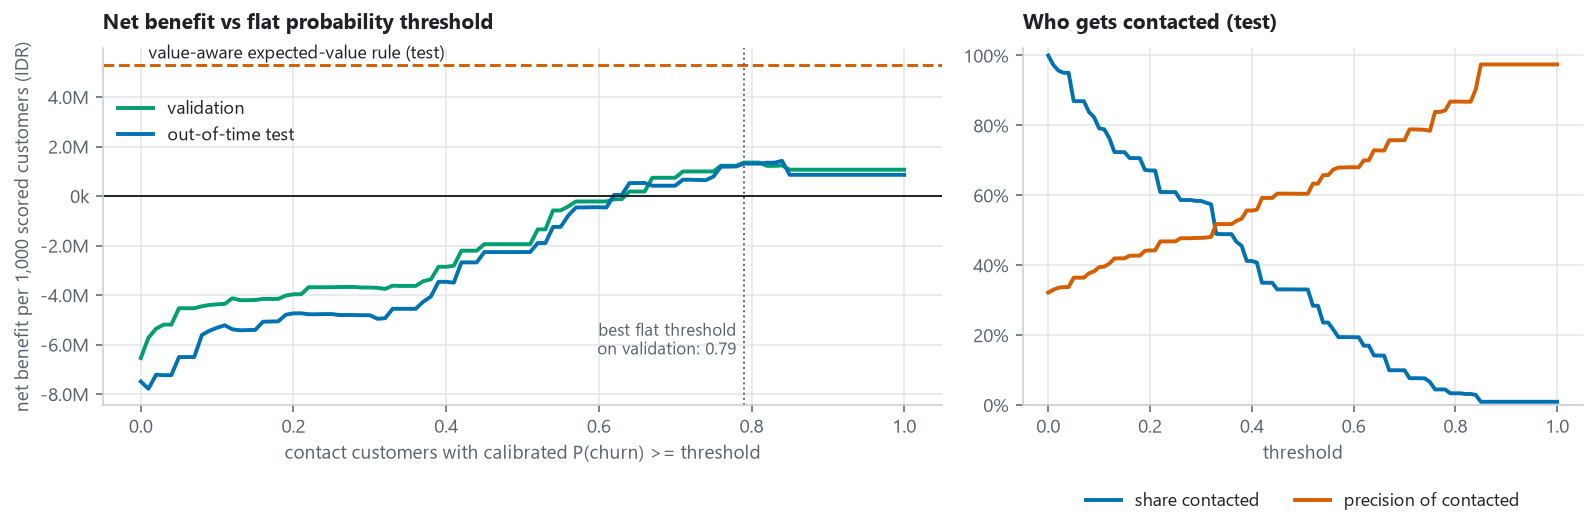

In [17]:
show("06_net_benefit_vs_threshold")

A flat probability threshold is a blunt tool because customers are worth very different amounts. The **expected-value rule** contacts customer *i* when `p_i * save_rate * value_i > contact_cost`, i.e. a customer-specific threshold `p_i >= contact_cost / (save_rate * value_i)`. Thresholds for the flat policy are picked on **validation** only, then scored on the untouched test set.

In [18]:
display(exp.policies.set_index("policy"))
rows = []
for key, name in [("flat", "flat threshold"), ("ev", "expected-value rule")]:
    r = exp.policy_ci[key]
    rows.append({"policy": name, "net benefit / 1,000 scored, 95% CI (IDR)": f"[{r['nb_per_1000_lo']:,.0f}, {r['nb_per_1000_hi']:,.0f}]",
                 "share of bootstrap resamples with profit > 0": r["prob_positive"]})
display(pd.DataFrame(rows).set_index("policy"))
print(f"break-even save rate: expected-value rule {exp.break_even_save_rate:.1%}, flat threshold {exp.break_even_save_rate_flat:.1%}")

,share_contacted,precision,net_benefit_per_run,net_benefit_per_1000_scored
policy,,,,
Contact nobody,0.000,NaN,0.000,0.000
Contact everyone,1.000,0.322,"-10,791,714.167","-7,492,511.571"
Top 10% by risk,0.100,0.758,"577,948.333","401,260.125"
Threshold p >= 0.79 (chosen on validation),0.033,0.868,"1,885,912.500","1,309,358.366"
Expected-value rule (per-customer),0.238,0.264,"7,640,008.333","5,304,333.488"


,"net benefit / 1,000 scored, 95% CI (IDR)",share of bootstrap resamples with profit > 0
policy,,
flat threshold,"[331,683, 2,772,618]",0.997
expected-value rule,"[2,611,387, 8,455,212]",1.000


break-even save rate: expected-value rule 9.2%, flat threshold 7.1%


In [19]:
display(exp.ev_by_value)

,median_value,median_break_even_p,share_contacted,churn_rate
quintile,,,,
Q1 (lowest value),"97,450.000",1.000,0.000,0.597
Q2,"251,225.000",0.929,0.024,0.451
Q3,"596,825.000",0.391,0.285,0.293
Q4,"1,346,000.000",0.173,0.439,0.184
Q5 (highest value),"3,963,100.000",0.059,0.444,0.083


### Sensitivity: what if the assumptions are wrong?

The policies are frozen as decided under the planning assumptions; the grid then varies the *actual* save rate and contact cost. This is the honest risk view: the expected-value rule has the larger upside but loses money if the offer works much worse than planned, whereas the high flat threshold contacts few customers and is hard to hurt (and hard to profit from).

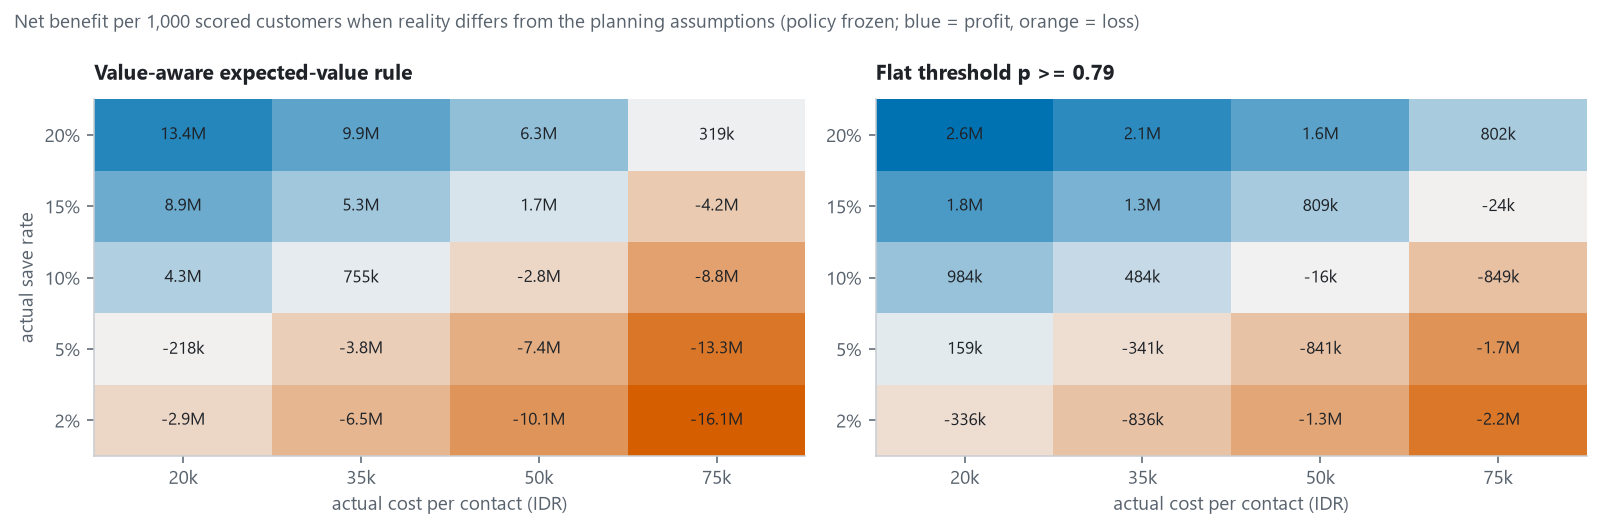

In [20]:
show("07_sensitivity")

## 8. Conclusions and limitations

In [21]:
t, ci_ = exp.test_metrics, exp.test_ci
sel = exp.selected
auc = ci_[(ci_.model == sel) & (ci_.metric == "AUC")].iloc[0]
p10 = ci_[(ci_.model == sel) & (ci_.metric == "Precision@10%")].iloc[0]
base = split.test[LABEL_COLUMN].mean()
ev = exp.policies[exp.policies.policy.str.startswith("Expected")].iloc[0]
fl = exp.policies[exp.policies.policy.str.startswith("Threshold")].iloc[0]
display(Markdown(f'''
**Findings (synthetic data, out-of-time test, {sel}).**

1. **Predictive power is real but moderate.** AUC {auc.point:.3f} (95% CI {auc.lo:.3f} to {auc.hi:.3f}); the top 10% riskiest rows churn {p10.point:.1%} of the time versus a base rate of {base:.1%}.
2. **Model differences are small.** The boosted trees and the Random Forest are within about {t['AUC'].max() - t.loc['Random Forest', 'AUC']:.3f} AUC of each other and logistic regression is only about {t['AUC'].max() - t.loc['Logistic Regression', 'AUC']:.3f} behind; interpretability may justify the simpler model.
3. **Leakage inflates results dramatically.** The same models reach AUC {exp.leakage['leaky_metrics']['AUC'].max():.3f} under the overlapping-window evaluation versus {t['AUC'].max():.3f} out-of-time.
4. **Probabilities are usable as probabilities.** Raw ECE is at most {exp.test_metrics_uncalibrated['ECE'].max():.3f} for every model. Isotonic recalibration on validation changes little for {sel} (ECE {exp.test_metrics_uncalibrated.loc[sel, 'ECE']:.3f} to {t.loc[sel, 'ECE']:.3f}) and helps logistic regression a bit ({exp.test_metrics_uncalibrated.loc['Logistic Regression', 'ECE']:.3f} to {t.loc['Logistic Regression', 'ECE']:.3f}), so it is a safeguard rather than a big win.
5. **Value-aware targeting beats a flat threshold** under the planning assumptions: {ev.net_benefit_per_1000_scored:,.0f} versus {fl.net_benefit_per_1000_scored:,.0f} IDR per 1,000 scored customers, but it needs a save rate above {exp.break_even_save_rate:.1%} to break even, so a randomised holdout test must come first.

**Limitations.** Synthetic data (conclusions about *this* simulation, not about any real shop); one out-of-time window of two months; the label ignores customers who simply order rarely; the expected-value policy contacts mostly high-value customers whose churn probability is below average, which only pays if the offer works on them; the economics are assumptions and the save rate is not identified from observational data (a churn model is not an uplift model); no hyper-parameter search beyond fixed, moderate settings.
'''))


**Findings (synthetic data, out-of-time test, XGBoost).**

1. **Predictive power is real but moderate.** AUC 0.800 (95% CI 0.783 to 0.817); the top 10% riskiest rows churn 76.0% of the time versus a base rate of 32.2%.
2. **Model differences are small.** The boosted trees and the Random Forest are within about 0.004 AUC of each other and logistic regression is only about 0.013 behind; interpretability may justify the simpler model.
3. **Leakage inflates results dramatically.** The same models reach AUC 0.990 under the overlapping-window evaluation versus 0.800 out-of-time.
4. **Probabilities are usable as probabilities.** Raw ECE is at most 0.047 for every model. Isotonic recalibration on validation changes little for XGBoost (ECE 0.032 to 0.033) and helps logistic regression a bit (0.047 to 0.037), so it is a safeguard rather than a big win.
5. **Value-aware targeting beats a flat threshold** under the planning assumptions: 5,304,333 versus 1,309,358 IDR per 1,000 scored customers, but it needs a save rate above 9.2% to break even, so a randomised holdout test must come first.

**Limitations.** Synthetic data (conclusions about *this* simulation, not about any real shop); one out-of-time window of two months; the label ignores customers who simply order rarely; the expected-value policy contacts mostly high-value customers whose churn probability is below average, which only pays if the offer works on them; the economics are assumptions and the save rate is not identified from observational data (a churn model is not an uplift model); no hyper-parameter search beyond fixed, moderate settings.
